# 9. Модель детектора в PyMC

В ноутбуке построена вероятностная модель задач 1–3 для источника с энергией 1 МэВ в центре сферического детектора. Распределение полного числа фотоэлектронов сравнивается с трассировкой лучей по методу задачи 4. Поглощение из задачи 6 можно включить переключателем `USE_ATTENUATION`.

In [3]:
%pip install -q pymc

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm

ENERGY_MEV = 1.0
LIGHT_YIELD = 10_000 
NUMBER_OF_PHOTONS = round(LIGHT_YIELD * ENERGY_MEV)
NUMBER_OF_EVENTS = 1_000 
DETECTOR_RADIUS_CM = 200.0
NUMBER_OF_PMTS = 40
PMT_RADIUS_CM = 10.0
PHOTOELECTRONS_PER_HIT = 0.5
ATTENUATION_LENGTH_CM = 800.0
USE_ATTENUATION = False
RANDOM_SEED = 42

indices = np.arange(NUMBER_OF_PMTS)
polar = np.arccos(1.0 - 2.0 * (indices + 0.5) / NUMBER_OF_PMTS)
azimuth = np.pi * (1.0 + np.sqrt(5.0)) * indices
pmt_normals = np.column_stack((
    np.cos(azimuth) * np.sin(polar),
    np.sin(azimuth) * np.sin(polar),
    np.cos(polar),
))

pmt_half_angle = np.arcsin(PMT_RADIUS_CM / DETECTOR_RADIUS_CM)
pairwise_angles = np.arccos(np.clip(pmt_normals @ pmt_normals.T, -1.0, 1.0))
np.fill_diagonal(pairwise_angles, np.inf)
assert pairwise_angles.min() > 2.0 * pmt_half_angle, "Сферические шапки фотокатодов перекрываются"

probability_per_pmt = (1.0 - np.cos(pmt_half_angle)) / 2.0
probability_of_hit = NUMBER_OF_PMTS * probability_per_pmt
attenuation_survival_probability = np.exp(-DETECTOR_RADIUS_CM / ATTENUATION_LENGTH_CM)
model_detection_probability = probability_of_hit * (
    attenuation_survival_probability if USE_ATTENUATION else 1.0
)

print(f"Фотонов на событие: {NUMBER_OF_PHOTONS}")
print(f"Вероятность попадания фотона без поглощения: {probability_of_hit:.6f}")
print(f"Вероятность выживания при поглощении: {attenuation_survival_probability:.6f}")
print(f"Режим поглощения: {'включен' if USE_ATTENUATION else 'выключен'}")

Фотонов на событие: 10000
Вероятность попадания фотона без поглощения: 0.025016
Вероятность выживания при поглощении: 0.778801
Режим поглощения: выключен


Источник в центре испускает изотропно `round(Y * E)` фотонов. Направление попадания в один фотокатод занимает сферическую шапку с косинусом полуугла `sqrt(1 - (r / R)^2)`, поэтому вероятность попадания в один фотокатод равна `(1 - sqrt(1 - (r / R)^2)) / 2`. Шапки для заданного расположения фотокатодов не перекрываются.

Следовательно, число попаданий имеет биномиальное распределение. Сумма откликов `Poisson(a)` от всех попавших фотонов также пуассоновская при известном числе попаданий. Это точное вероятностное сокращение модели задач 1–3 для источника в центре; отдельная симуляция лучей ниже проверяет геометрическое приближение.

In [14]:
with pm.Model() as detector_model:
    detected_photons = pm.Binomial(
        "detected_photons",
        n=NUMBER_OF_PHOTONS,
        p=model_detection_probability,
    )
    photoelectrons = pm.Poisson(
        "photoelectrons",
        mu=PHOTOELECTRONS_PER_HIT * detected_photons,
    )
    predictive = pm.sample_prior_predictive(
        samples=NUMBER_OF_EVENTS,
        var_names=["photoelectrons"],
        random_seed=RANDOM_SEED,
    )

pymc_charges = predictive.prior["photoelectrons"].values.reshape(-1).astype(np.int64)
assert len(pymc_charges) == NUMBER_OF_EVENTS
print(f"Смоделировано событий PyMC: {len(pymc_charges)}")

Sampling: [detected_photons, photoelectrons]


Смоделировано событий PyMC: 1000


В следующей ячейке воспроизводится геометрическая проверка задачи 4: для каждого фотона генерируется изотропное направление, находится точка пересечения со сферой, а попадание в фотокатод проверяется проекцией на его нормаль. Как и в задаче 4, число фотонов фиксировано, а суммарный отклик при `h` попаданиях разыгрывается как `Poisson(a * h)`.

In [15]:
def simulate_task4_reference(rng, number_of_events, attenuation_length_cm=None, event_batch_size=8):
    """Трассировка лучей от центра сферы по геометрии задачи 4."""
    projection_threshold = np.sqrt(DETECTOR_RADIUS_CM**2 - PMT_RADIUS_CM**2)
    charges = np.empty(number_of_events, dtype=np.int64)

    for batch_start in range(0, number_of_events, event_batch_size):
        batch_end = min(batch_start + event_batch_size, number_of_events)
        batch_events = batch_end - batch_start
        photon_count = batch_events * NUMBER_OF_PHOTONS

        cos_theta = rng.uniform(-1.0, 1.0, photon_count)
        phi = rng.uniform(0.0, 2.0 * np.pi, photon_count)
        sin_theta = np.sqrt(1.0 - cos_theta**2)
        directions = np.column_stack((
            sin_theta * np.cos(phi),
            sin_theta * np.sin(phi),
            cos_theta,
        ))
        boundary_points = DETECTOR_RADIUS_CM * directions
        projections = boundary_points @ pmt_normals.T
        hits = np.any(projections >= projection_threshold, axis=1)

        if attenuation_length_cm is not None:
            if attenuation_length_cm <= 0:
                raise ValueError("Длина затухания должна быть положительной")
            survives = rng.random(photon_count) < np.exp(
                -DETECTOR_RADIUS_CM / attenuation_length_cm
            )
            hits &= survives

        hits_per_event = hits.reshape(batch_events, NUMBER_OF_PHOTONS).sum(axis=1)
        charges[batch_start:batch_end] = rng.poisson(
            lam=PHOTOELECTRONS_PER_HIT * hits_per_event
        )

    return charges


task4_charges = simulate_task4_reference(
    np.random.default_rng(RANDOM_SEED + 1),
    NUMBER_OF_EVENTS,
)

if USE_ATTENUATION:
    ray_charges = simulate_task4_reference(
        np.random.default_rng(RANDOM_SEED + 2),
        NUMBER_OF_EVENTS,
        attenuation_length_cm=ATTENUATION_LENGTH_CM,
    )
else:
    ray_charges = task4_charges

effective_detection_probability = model_detection_probability
expected_mean = (
    NUMBER_OF_PHOTONS
    * effective_detection_probability
    * PHOTOELECTRONS_PER_HIT
)
expected_variance = NUMBER_OF_PHOTONS * effective_detection_probability * (
    PHOTOELECTRONS_PER_HIT
    + PHOTOELECTRONS_PER_HIT**2 * (1.0 - effective_detection_probability)
)

print("Распределение полного числа фотоэлектронов")
print(f"Теория:         среднее = {expected_mean:.2f}, σ = {np.sqrt(expected_variance):.2f}")
print(f"PyMC:           среднее = {pymc_charges.mean():.2f}, σ = {pymc_charges.std(ddof=1):.2f}")
print(f"Трассировка:    среднее = {ray_charges.mean():.2f}, σ = {ray_charges.std(ddof=1):.2f}")
print(f"Задача 4 (без поглощения): среднее = {task4_charges.mean():.2f}, σ = {task4_charges.std(ddof=1):.2f}")

Распределение полного числа фотоэлектронов
Теория:         среднее = 125.08, σ = 13.64
PyMC:           среднее = 125.77, σ = 14.02
Трассировка:    среднее = 124.48, σ = 13.38
Задача 4 (без поглощения): среднее = 124.48, σ = 13.38


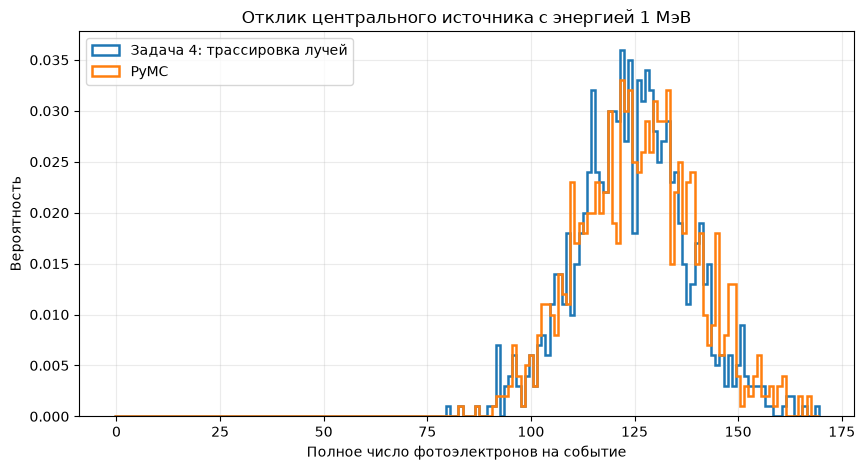

In [16]:
all_charges = [task4_charges, pymc_charges]
labels = ["Задача 4: трассировка лучей", "PyMC"]
if USE_ATTENUATION:
    all_charges.append(ray_charges)
    labels.append("Трассировка с поглощением")

upper_edge = max(int(charges.max()) for charges in all_charges) + 1
bins = np.arange(-0.5, upper_edge + 0.5, 1)
fig, ax = plt.subplots(figsize=(10, 5))
for charges, label in zip(all_charges, labels):
    ax.hist(charges, bins=bins, density=True, histtype="step", linewidth=1.8, label=label)
ax.set(
    xlabel="Полное число фотоэлектронов на событие",
    ylabel="Вероятность",
    title="Отклик центрального источника с энергией 1 МэВ",
)
ax.legend()
ax.grid(alpha=0.25)
plt.show()

При выключенном поглощении результаты PyMC и трассировки должны согласовываться в пределах статистических флуктуаций выборок. При включении `USE_ATTENUATION` в модели применяется вероятность выживания `exp(-R / λ)` с параметром из задачи 6 (`λ = 800 см`); на графике при этом показаны PyMC, трассировка с поглощением и базовое распределение задачи 4 без поглощения.